In [ ]:
# mount a google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/heart_disease.csv')
df.head()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


In [ ]:
df.shape
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   object 
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   object 
 5   Smoking               9975 non-null   object 
 6   Family Heart Disease  9979 non-null   object 
 7   Diabetes              9970 non-null   object 
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   object 
 10  Low HDL Cholesterol   9975 non-null   object 
 11  High LDL Cholesterol  9974 non-null   object 
 12  Alcohol Consumption   7414 non-null   object 
 13  Stress Level          9978 non-null   object 
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption   

,0
Age,29
Gender,19
Blood Pressure,19
Cholesterol Level,30
Exercise Habits,25
Smoking,25
Family Heart Disease,21
Diabetes,30
BMI,22
High Blood Pressure,26


In [ ]:
df.columns


Index(['Age', 'Gender', 'Blood Pressure', 'Cholesterol Level',
       'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'BMI',
       'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol',
       'Alcohol Consumption', 'Stress Level', 'Sleep Hours',
       'Sugar Consumption', 'Triglyceride Level', 'Fasting Blood Sugar',
       'CRP Level', 'Homocysteine Level', 'Heart Disease Status'],
      dtype='object')

In [ ]:
for col in df.columns:
    print(repr(col))

'Age'
'Gender'
'Blood Pressure'
'Cholesterol Level'
'Exercise Habits'
'Smoking'
'Family Heart Disease'
'Diabetes'
'BMI'
'High Blood Pressure'
'Low HDL Cholesterol'
'High LDL Cholesterol'
'Alcohol Consumption'
'Stress Level'
'Sleep Hours'
'Sugar Consumption'
'Triglyceride Level'
'Fasting Blood Sugar'
'CRP Level'
'Homocysteine Level'
'Heart Disease Status'


In [ ]:
for i, col in enumerate(df.columns):
    print(i, repr(col))

0 'Age'
1 'Gender'
2 'Blood Pressure'
3 'Cholesterol Level'
4 'Exercise Habits'
5 'Smoking'
6 'Family Heart Disease'
7 'Diabetes'
8 'BMI'
9 'High Blood Pressure'
10 'Low HDL Cholesterol'
11 'High LDL Cholesterol'
12 'Alcohol Consumption'
13 'Stress Level'
14 'Sleep Hours'
15 'Sugar Consumption'
16 'Triglyceride Level'
17 'Fasting Blood Sugar'
18 'CRP Level'
19 'Homocysteine Level'
20 'Heart Disease Status'


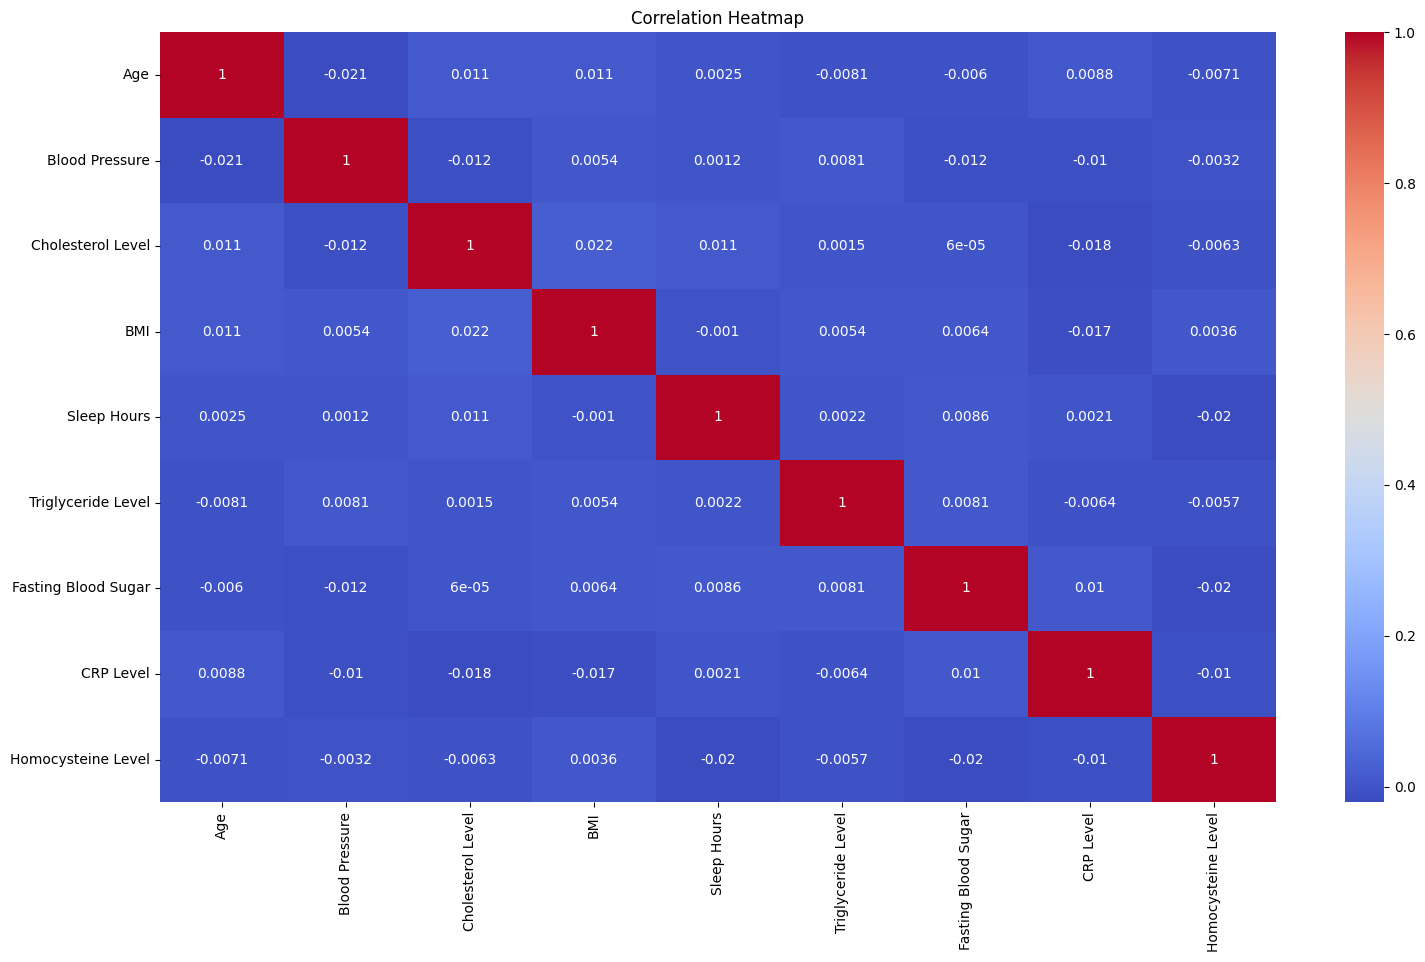

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18,10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Index(['Age', 'Gender', 'Blood_Pressure', 'Cholesterol_Level',
       'Exercise_Habits', 'Smoking', 'Family_Heart_Disease', 'Diabetes', 'BMI',
       'High_Blood_Pressure', 'Low_HDL_Cholesterol', 'High_LDL_Cholesterol',
       'Alcohol_Consumption', 'Stress_Level', 'Sleep_Hours',
       'Sugar_Consumption', 'Triglyceride_Level', 'Fasting_Blood_Sugar',
       'CRP_Level', 'Homocysteine_Level', 'Heart_Disease_Status'],
      dtype='object')


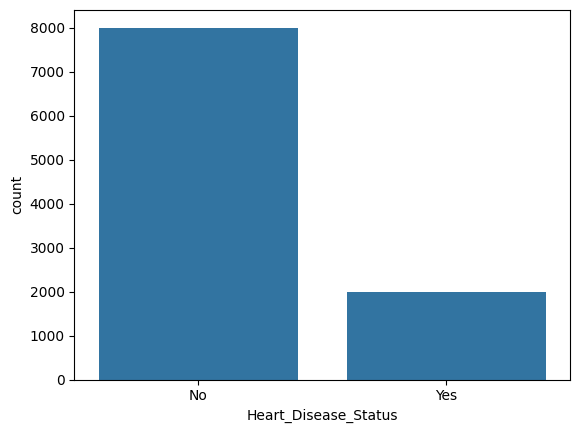

In [ ]:
df.columns = df.columns.str.strip().str.replace(r'\s+', '_', regex=True)
print(df.columns)
sns.countplot(x='Heart_Disease_Status', data=df)
plt.show()

In [ ]:
#fixing target column name
df.columns = df.columns.str.strip()
df.rename(columns={'Heart Disease Status': 'target'}, inplace=True)
df['target'].value_counts()

,count
target,
No,8000
Yes,2000


In [ ]:
# Diagnostic: see object columns and a sample of their unique values
obj_cols = df.select_dtypes(include=['object']).columns.tolist()
print("Object columns:", obj_cols, "\n")

for col in obj_cols:
    print(col, "-> uniques (sample):", df[col].dropna().unique()[:20])
    print("  #nulls:", df[col].isna().sum(), "  dtype:", df[col].dtype)
    print('-'*60)

Object columns: [] 



In [ ]:
for col in obj_cols:
    # try to convert to numeric — if conversion succeeds with many non-NaNs, keep numeric
    coerced = pd.to_numeric(df[col], errors='coerce')
    non_na_ratio = coerced.notna().sum() / len(coerced)
    if non_na_ratio > 0.6:   # threshold: if >60% convertible to numeric, convert column
        df[col] = coerced
        print(f"Converted {col} -> numeric (non-na ratio {non_na_ratio:.2f})")
    else:
        print(f"Left {col} as categorical (non-na ratio {non_na_ratio:.2f})")

In [ ]:
# make sure 'target' exists
assert 'target' in df.columns, "target column not found — check your rename step."

# categorical = object types OR integer columns with few unique values (like 0/1 or small categories)
cat_cols = list(df.select_dtypes(include=['object']).columns)

# also include integer columns that are categorical (optional heuristic)
for col in df.select_dtypes(include=['int64','float64']).columns:
    if col == 'target':
        continue
    if df[col].nunique() <= 6:   # heuristic: <=6 unique values might be categorical
        cat_cols.append(col)

cat_cols = sorted(list(set(cat_cols)))
print("Final categorical columns to encode:", cat_cols)

Final categorical columns to encode: ['Alcohol Consumption', 'Diabetes', 'Exercise Habits', 'Family Heart Disease', 'Gender', 'High Blood Pressure', 'High LDL Cholesterol', 'Low HDL Cholesterol', 'Smoking', 'Stress Level', 'Sugar Consumption']


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (8000, 20)
Testing set shape: (2000, 20)


In [4]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

# Load df and apply necessary transformations to ensure 'target' column exists
df = pd.read_csv('/content/drive/MyDrive/heart_disease.csv')
df.columns = df.columns.str.strip().str.replace(r'\s+', '_', regex=True)
df.rename(columns={'Heart_Disease_Status': 'target'}, inplace=True) # Corrected rename for 'Heart_Disease_Status'

# Ensure X, y, X_train, y_train are defined
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include=['object']).columns

# Create preprocessing pipelines for numerical and categorical features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Create a column transformer to apply different transformations to different columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
])

# Create a pipeline with preprocessing and the Logistic Regression model
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

# Create a pipeline with preprocessing and the Random Forest Classifier model
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=200, random_state=42))
])

# Fit the pipelines
logreg_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

print("Models trained successfully.")


Models trained successfully.



Model: Logistic Regression
Accuracy: 0.8065

Classification Report:
               precision    recall  f1-score   support

           0       0.81      1.00      0.89      1613
           1       0.00      0.00      0.00       387

    accuracy                           0.81      2000
   macro avg       0.40      0.50      0.45      2000
weighted avg       0.65      0.81      0.72      2000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


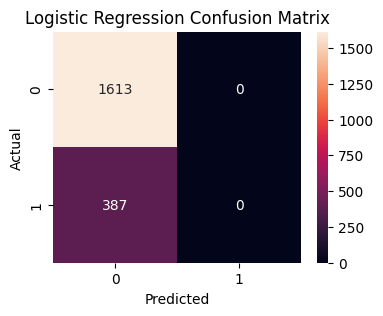


Model: Random Forest
Accuracy: 0.8065

Classification Report:
               precision    recall  f1-score   support

           0       0.81      1.00      0.89      1613
           1       0.00      0.00      0.00       387

    accuracy                           0.81      2000
   macro avg       0.40      0.50      0.45      2000
weighted avg       0.65      0.81      0.72      2000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


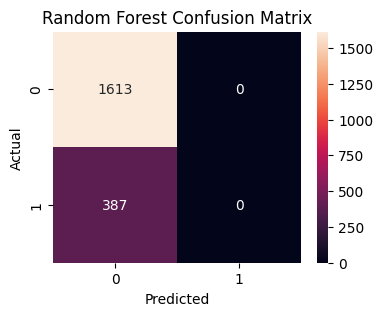

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

models = {'Logistic Regression': logreg_pipeline, 'Random Forest': rf_pipeline}

for name, model in models.items():
    print("\n===============================")
    print(f"Model: {name}")
    print("===============================")

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    # Confusion matrix heatmap
    plt.figure(figsize=(4,3))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
    plt.title(f'{name} Confusion Matrix')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()